# EDA: Label Distribution ("pole")

This notebook analyzes YOLO labels across datasets in `dataset/Poles2025`.

It includes:
- Number of labeled objects by dataset and split
- Distribution of box centers (`x_center`, `y_center`) and sizes (`width`, `height`)
- **Min, max, and average position** of `pole` within the frame (normalized coordinates in `[0, 1]`)

In [6]:
from pathlib import Path
import re
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT_DIR = Path(".")
DATASET_ROOT = ROOT_DIR / "dataset" / "Poles2025"

pd.set_option("display.max_columns", 100)

print(f"Dataset root: {DATASET_ROOT.resolve()}")

Dataset root: /home/chongy/stuff/codespace/snowpole-detection-ad/dataset/Poles2025


In [7]:
def parse_names_field(names_field):
    if isinstance(names_field, dict):
        return {int(k): str(v) for k, v in names_field.items()}
    if isinstance(names_field, list):
        return {i: str(v) for i, v in enumerate(names_field)}
    return {}


def infer_split_from_path(path: Path):
    parts = [p.lower() for p in path.parts]
    if "train" in parts:
        return "train"
    if "validation" in parts or "val" in parts or "valid" in parts:
        return "valid"
    if "test" in parts:
        return "test"
    return "unknown"


def looks_like_yolo_label_file(path: Path):
    if path.suffix.lower() != ".txt":
        return False
    if path.name.lower() in {"train.txt", "validation.txt", "val.txt", "test.txt"}:
        return False

    try:
        lines = [ln.strip() for ln in path.read_text().splitlines() if ln.strip()]
    except Exception:
        return False

    if not lines:
        return False

    sample = lines[: min(5, len(lines))]
    pattern = re.compile(r"^-?\d+\s+[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?\s+[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?\s+[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?\s+[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?(?:\s+.*)?$")
    return all(pattern.match(ln) for ln in sample)


def read_yolo_labels(dataset_dir: Path):
    data_yaml = dataset_dir / "data.yaml"
    if not data_yaml.exists():
        return pd.DataFrame(), {}

    meta = yaml.safe_load(data_yaml.read_text()) or {}
    class_map = parse_names_field(meta.get("names", {}))

    rows = []
    for txt in dataset_dir.rglob("*.txt"):
        if not looks_like_yolo_label_file(txt):
            continue

        rel = txt.relative_to(dataset_dir)
        split = infer_split_from_path(rel)

        for line_no, line in enumerate(txt.read_text().splitlines(), start=1):
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            if len(parts) < 5:
                continue
            try:
                cls_id = int(float(parts[0]))
                x_center, y_center, width, height = map(float, parts[1:5])
            except ValueError:
                continue

            rows.append(
                {
                    "dataset": dataset_dir.name,
                    "split": split,
                    "label_file": str(rel),
                    "line_no": line_no,
                    "class_id": cls_id,
                    "class_name": class_map.get(cls_id, str(cls_id)),
                    "x_center": x_center,
                    "y_center": y_center,
                    "width": width,
                    "height": height,
                    "area": width * height,
                }
            )

    return pd.DataFrame(rows), class_map


def collect_all_labels(dataset_root: Path):
    dfs = []
    class_maps = {}

    for data_yaml in dataset_root.rglob("data.yaml"):
        dataset_dir = data_yaml.parent
        df_ds, cmap = read_yolo_labels(dataset_dir)
        if not df_ds.empty:
            dfs.append(df_ds)
            class_maps[dataset_dir.name] = cmap

    if not dfs:
        return pd.DataFrame(), class_maps

    return pd.concat(dfs, ignore_index=True), class_maps

In [8]:
df, class_maps = collect_all_labels(DATASET_ROOT)

if df.empty:
    raise RuntimeError("No YOLO label annotations found under dataset/Poles2025.")

print("Detected datasets:", sorted(df["dataset"].unique().tolist()))
print("Total labeled objects:", len(df))
print("Class maps:")
for ds, cmap in class_maps.items():
    print(f"  - {ds}: {cmap}")

display(df.head())

Detected datasets: ['Road_poles_iPhone', 'roadpoles_v1']
Total labeled objects: 2004
Class maps:
  - Road_poles_iPhone: {0: 'pole'}
  - roadpoles_v1: {0: 'pole'}


,dataset,split,label_file,line_no,class_id,class_name,x_center,y_center,width,height,area
0,Road_poles_iPhone,valid,labels/Validation/val/920914962.txt,1,0,pole,0.803269,0.557484,0.014389,0.042906,0.000617
1,Road_poles_iPhone,valid,labels/Validation/val/920841524.txt,1,0,pole,0.974384,0.576885,0.034194,0.064698,0.002212
2,Road_poles_iPhone,valid,labels/Validation/val/921240180.txt,1,0,pole,0.284977,0.545763,0.015287,0.034911,0.000534
3,Road_poles_iPhone,valid,labels/Validation/val/920004953.txt,1,0,pole,0.760213,0.552039,0.023259,0.060578,0.001409
4,Road_poles_iPhone,valid,labels/Validation/val/921516866.txt,1,0,pole,0.182653,0.564289,0.011157,0.053026,0.000592


In [9]:
# Focus on poles (case-insensitive). Falls back to all rows if class names are numeric.
is_pole = df["class_name"].astype(str).str.lower().eq("pole")
pole_df = df[is_pole].copy()
if pole_df.empty:
    pole_df = df.copy()

print(f"Rows used for pole analysis: {len(pole_df):,}")

# Count distribution
count_by_dataset_split = (
    pole_df.groupby(["dataset", "split"], dropna=False)
    .size()
    .rename("n_boxes")
    .reset_index()
    .sort_values(["dataset", "split"])
)
display(count_by_dataset_split)

# Position + size stats in normalized coordinates
summary = pole_df[["x_center", "y_center", "width", "height", "area"]].agg(["min", "max", "mean", "median", "std"]).T
summary = summary.rename(columns={"mean": "avg"})
display(summary)

# Explicit min / max / average position requested
position_stats = pd.DataFrame(
    {
        "metric": ["x_center", "y_center"],
        "min": [pole_df["x_center"].min(), pole_df["y_center"].min()],
        "max": [pole_df["x_center"].max(), pole_df["y_center"].max()],
        "avg": [pole_df["x_center"].mean(), pole_df["y_center"].mean()],
    }
)
print("Pole position in frame (normalized):")
display(position_stats)

# Optional: per-dataset position summary
per_dataset_position = (
    pole_df.groupby("dataset")[["x_center", "y_center"]]
    .agg(["min", "max", "mean"])
)
display(per_dataset_position)

Rows used for pole analysis: 2,004


,dataset,split,n_boxes
0,Road_poles_iPhone,train,1169
1,Road_poles_iPhone,valid,330
2,roadpoles_v1,train,392
3,roadpoles_v1,valid,113


,min,max,avg,median,std
x_center,0.003414,0.991641,0.545909,0.665509,0.307627
y_center,0.475680,0.730339,0.571117,0.565357,0.030204
width,0.001875,0.076708,0.015625,0.013166,0.010774
height,0.015812,0.435844,0.073016,0.060450,0.050140
area,0.000075,0.032765,0.001189,0.000731,0.001760


Pole position in frame (normalized):


,metric,min,max,avg
0,x_center,0.003414,0.991641,0.545909
1,y_center,0.475680,0.730339,0.571117


x_center                      y_center                   
                        min       max      mean       min       max     mean
dataset                                                                     
Road_poles_iPhone  0.005394  0.987032  0.574943  0.475680  0.610956  0.55909
roadpoles_v1       0.003414  0.991641  0.459725  0.560389  0.730339  0.60682

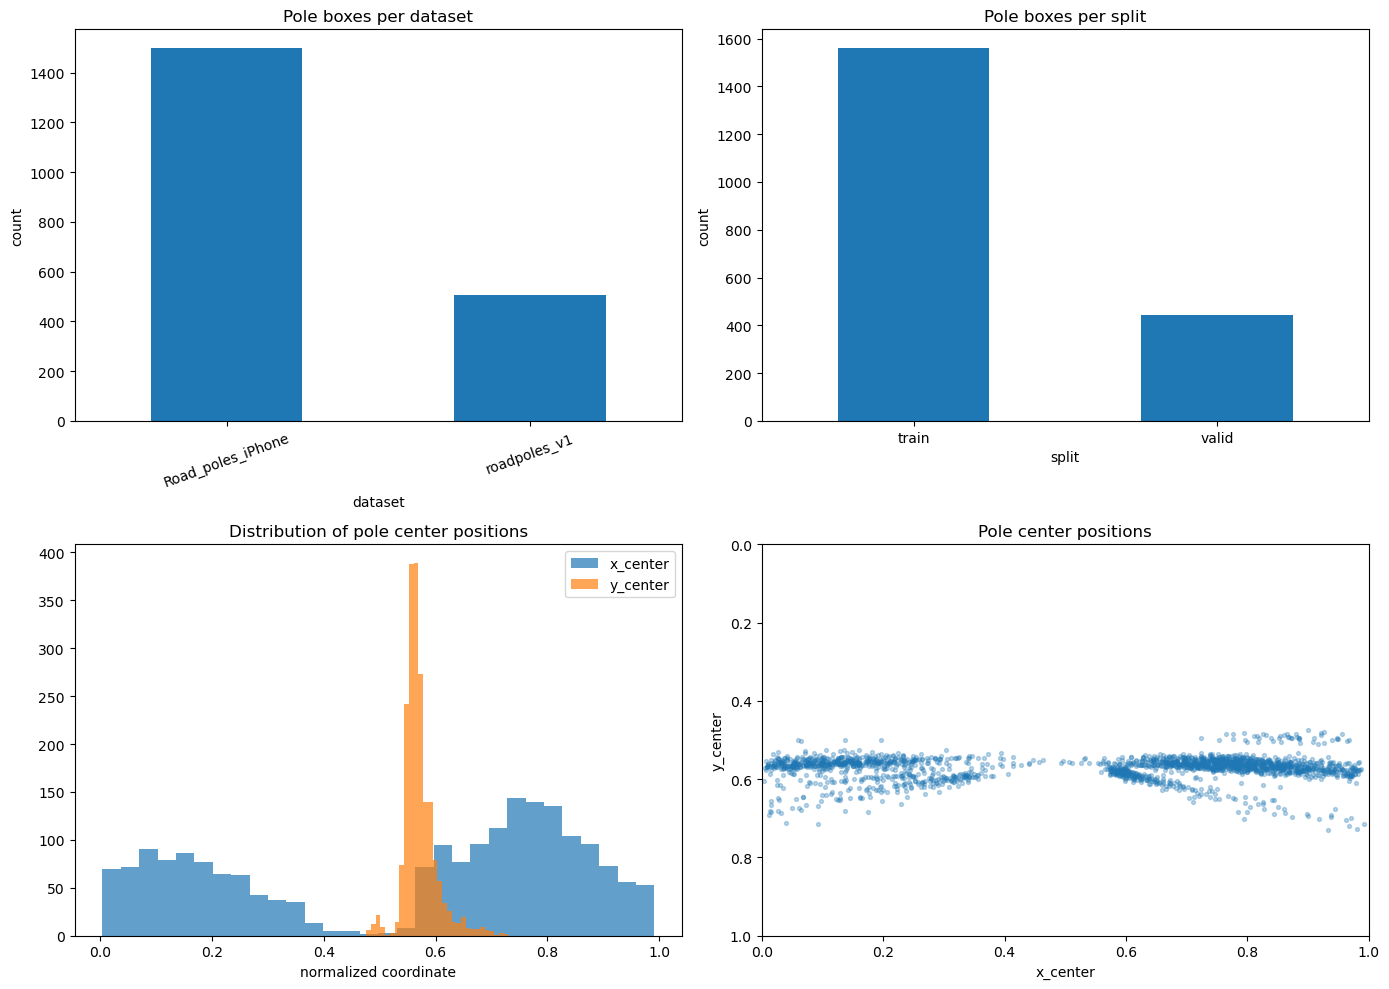

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Count of boxes by dataset
(
    pole_df.groupby("dataset").size().sort_values(ascending=False)
    .plot(kind="bar", ax=axes[0, 0], title="Pole boxes per dataset")
)
axes[0, 0].set_ylabel("count")
axes[0, 0].tick_params(axis="x", rotation=20)

# 2) Count of boxes by split
(
    pole_df.groupby("split").size().reindex(["train", "valid", "test", "unknown"]).dropna()
    .plot(kind="bar", ax=axes[0, 1], title="Pole boxes per split")
)
axes[0, 1].set_ylabel("count")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3) Histograms of center positions
axes[1, 0].hist(pole_df["x_center"], bins=30, alpha=0.7, label="x_center")
axes[1, 0].hist(pole_df["y_center"], bins=30, alpha=0.7, label="y_center")
axes[1, 0].set_title("Distribution of pole center positions")
axes[1, 0].set_xlabel("normalized coordinate")
axes[1, 0].legend()

# 4) Spatial distribution scatter
sample_scatter = pole_df
axes[1, 1].scatter(sample_scatter["x_center"], sample_scatter["y_center"], s=8, alpha=0.3)
axes[1, 1].set_title("Pole center positions")
axes[1, 1].set_xlabel("x_center")
axes[1, 1].set_ylabel("y_center")
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].invert_yaxis()  # image coordinate convention

plt.tight_layout()
plt.show()